# Estimación puntual: insesgamiento, eficiencia y máxima verosimilitud

Desarrollo de los ejercicios de estimación de parámetros poblacionales: estimadores puntuales de
media, varianza, desviación estándar y proporción; propiedades de los estimadores (sesgo, varianza,
error cuadrático medio y eficiencia relativa); y método de máxima verosimilitud para los parámetros
de las distribuciones de Poisson, binomial y normal. Los cálculos se hacen en Python con `numpy`; las
propiedades muestrales se contrastan por simulación Monte Carlo con semilla fija y los estimadores se
comparan gráficamente por sus distribuciones muestrales.

## Marco teórico

### Parámetro, estimador y sesgo

Sea $\theta$ un parámetro desconocido de una población y $X_1, X_2, \dots, X_n$ una muestra aleatoria
de ella. Un **estimador** es una variable aleatoria $T = T(X_1, \dots, X_n)$; el número que resulta de
sustituir las observaciones se llama **estimación** o punto muestreo, $t = T(x_1, \dots, x_n)$. Como
$T$ depende de la muestra, varía de una muestra a otra: esa dispersión forma parte de la calidad del
estimador y no puede ignorarse al interpretar un valor puntual.

El **sesgo** mide el desplazamiento sistemático del estimador respecto del parámetro:

$$b(T) = E[T] - \theta$$

El estimador es **insesgado** cuando $b(T) = 0$, es decir cuando su valor esperado coincide con el
parámetro para todo valor posible de $\theta$. Si el sesgo depende de $n$ y tiende a cero al crecer la
muestra, el estimador es asintóticamente insesgado.

### Varianza del estimador y error cuadrático medio

La dispersión de $T$ alrededor de su valor esperado se mide por $\operatorname{Var}(T)$. La calidad
global se resume en el **error cuadrático medio**, que descompone en varianza más sesgo al cuadrado:

$$\operatorname{ECM}(T) = E\left[(T - \theta)^2\right] = \operatorname{Var}(T) + \left[b(T)\right]^2$$

Para dos estimadores insesgados del mismo parámetro el ECM se reduce a la varianza, de modo que
impera el de menor dispersión. No hay orden total entre estimadores: uno puede ser insesgado pero muy
variable y otro sesgado con menor ECM; compararlos exige fijar el criterio.

### Eficiencia relativa

Sean $T_1$ y $T_2$ dos estimadores insesgados del mismo parámetro, ambos con varianza finita. La
**eficiencia relativa** de $T_1$ con respecto de $T_2$ es el cociente inverso de sus varianzas:

$$\operatorname{EFF}(T_1, T_2) = \frac{\operatorname{Var}(T_2)}{\operatorname{Var}(T_1)}$$

Si $\operatorname{EFF}(T_1, T_2) > 1$, entonces $T_1$ es más eficiente: su distribución muestral es más
concentrada alrededor del parámetro y, con el mismo tamaño de muestra, produce estimaciones más
próximas a $\theta$. El cociente admite lectura de tamaño de muestra equivalente: igualar la varianza
de $T_2$ con $T_1$ requiere $n_1 = n_2/\operatorname{EFF}$ observaciones. Un estimador insesgado con
varianza mínima entre los insesgados se denomina **eficiente** (mínima varianza insesgado).

### Estimadores puntuales usuales

| Parámetro | Estimador | Valor esperado | Varianza | ¿Insesgado? |
|---|---|---|---|---|
| $\mu$ | $\bar{X} = \dfrac{1}{n}\sum_{i=1}^{n} X_i$ | $\mu$ | $\dfrac{\sigma^2}{n}$ | sí |
| $\sigma^2$ | $S^2 = \dfrac{1}{n-1}\sum_{i=1}^{n}(X_i - \bar{X})^2$ | $\sigma^2$ | $\dfrac{1}{n}\left(\mu_4 - \dfrac{n-3}{n-1}\sigma^4\right)$ | sí |
| $\sigma$ | $S = \sqrt{S^2}$ | $E[S] < \sigma$ | $-$ | no |
| $p$ | $\hat{p} = X/n$ | $p$ | $\dfrac{p(1-p)}{n}$ | sí |

con $\mu_4 = E\left[(X - \mu)^4\right]$. El denominador $n - 1$ de $S^2$ corrige el sesgo que introduce
dividir por $n$: el estimador $B_2 = \dfrac{n-1}{n}S^2$, es decir la varianza con denominador $n$,
cumple $E[B_2] = \dfrac{n-1}{n}\sigma^2$, con sesgo $-\sigma^2/n$. La raíz cuadrada rompe el
insesgamiento porque es cóncava: la desigualdad de Jensen da
$E[S] = E[\sqrt{S^2}] \le \sqrt{E[S^2]} = \sigma$, con desigualdad estricta mientras
$\operatorname{Var}(S^2) > 0$. La proporción muestral $\hat p$ es la media muestral de las variables
indicadoras de la característica, de donde hereda su insesgamiento y su varianza.

### Consistencia

$T$ es **consistente** cuando se acerca al parámetro a medida que crece la muestra:
$P(|T - \theta| > \varepsilon) \to 0$ para todo $\varepsilon > 0$ cuando $n \to \infty$. Para
$\bar{X}$ se deduce de la desigualdad de Chebyshev, ya que $\operatorname{Var}(\bar{X}) = \sigma^2/n$
tiende a cero; en general, un estimador insesgado cuya varianza se anula asintóticamente es
consistente. Insesgamiento y consistencia son propiedades distintas: la primera es finita, la segunda
asintótica.

### Método de máxima verosimilitud

Dada una muestra aleatoria con masa o densidad $f(x;\theta)$ y $\theta$ desconocido, la **función de
verosimilitud** mide el ajuste de cada candidato de parámetro a los datos observados:

$$L(\theta) = \prod_{i=1}^{n} f(x_i;\theta)$$

El producto es numéricamente frágil y el máximo no cambia al aplicar una transformación creciente, de
modo que se maximiza el **logaritmo de verosimilitud**, que convierte el producto en suma:

$$\ell(\theta) = \ln L(\theta) = \sum_{i=1}^{n} \ln f(x_i;\theta)$$

Si $\ell$ es diferenciable, el **estimador máximo verosímil** (EMV) resuelve la ecuación de
verosimilitad, o función score,

$$\frac{d\ell(\theta)}{d\theta} = 0$$

y se comprueba que el punto estacionario es un máximo: $\ell''(\theta) < 0$ en el caso univariado, o
matriz hessiana negativa definida cuando hay varios parámetros.

### Verosimilitudes de referencia

| Modelo | Masa o densidad | Log-verosimilitud |
|---|---|---|
| Poisson | $\dfrac{e^{-\lambda}\lambda^{x}}{x!},\quad x = 0, 1, 2, \dots$ | $-n\lambda + \left(\sum x_i\right)\ln\lambda - \sum \ln(x_i!)$ |
| Binomial | $C(n,x)\, p^{x}(1-p)^{n-x},\quad x = 0, \dots, n$ | $\ln C(n,x) + x\ln p + (n-x)\ln(1-p)$ |
| Normal | $\dfrac{1}{\sqrt{2\pi\sigma^2}}\exp\left[-\dfrac{(x-\mu)^2}{2\sigma^2}\right]$ | $-\dfrac{n}{2}\ln(2\pi\sigma^2) - \dfrac{1}{2\sigma^2}\sum(x_i - \mu)^2$ |

En la binomial el experimento aporta dos datos, los éxitos $x$ y el número de ensayos $n$; en la normal
hay dos parámetros desconocidos, $(\mu, \sigma^2)$, y la verosimilitud se maximiza resolviendo un
sistema de dos ecuaciones por derivadas parciales.

In [1]:
import math

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

AZUL = "#1f4e79"
GRIS = "#808080"
VERDE = "#2e7d32"
ROJO = "#b03a2e"

print("numpy", np.__version__, "| matplotlib", mpl.__version__)


numpy 2.4.4 | matplotlib 3.10.9


## 1. Peso de latas de arvejas: estimaciones puntuales

Una máquina enlatadora produce latas cuyo peso nominal es de 800 g. El supervisor toma una muestra
aleatoria de $n = 10$ latas y registra los pesos en gramos:

| $i$ | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|---|
| $x_i$ (g) | 796 | 790 | 798 | 801 | 797 | 796 | 803 | 802 | 804 | 802 |

El muestreo es aleatorio simple, de modo que las observaciones son independientes e idénticamente
distribuidas con media $\mu$ y varianza $\sigma^2$ finitas. Los parámetros a estimar son el peso
promedio $\mu$, la variabilidad cuadrática promedio $\sigma^2$, la desviación estándar $\sigma$ y la
proporción $p$ de latas que pesan más de 800 g.

### a) Estimaciones puntuales

1. **Peso promedio de todas las latas.** Se usa la media muestral, $\hat\mu = \bar x$, insesgada para
   $\mu$ y con varianza $\sigma^2/n$:

$$\bar x = \frac{1}{n}\sum_{i=1}^{n} x_i$$

2. **Variabilidad cuadrática promedio.** Es la varianza poblacional, el promedio de las desviaciones
   al cuadrado respecto de $\mu$. El estimador insesgado es la varianza muestral con denominador
   $n - 1$:

$$s^2 = \frac{1}{n-1}\sum_{i=1}^{n} (x_i - \bar x)^2$$

   La suma de cuadrados se evalúa en la forma computacionalmente estable
   $\sum (x_i - \bar x)^2 = \sum x_i^2 - \left(\sum x_i\right)^2/n$, que evita restar dos sumatorias
   grandes y perder cifras significativas.
3. **Desviación estándar de los pesos.** Es la raíz de la varianza muestral, $s = \sqrt{s^2}$, en las
   mismas unidades del peso. Es la estimación natural de $\sigma$, aunque no resulta insesgada (ver el
   inciso b).
4. **Proporción de latas sobre 800 g.** Sean $y_i = 1$ si la lata $i$ pesa más de 800 g y $y_i = 0$
   en caso contrario. La estimación es la proporción muestral:

$$\hat p = \bar y = \frac{1}{n}\sum_{i=1}^{n} y_i$$

In [2]:
latas = np.array([796, 790, 798, 801, 797, 796, 803, 802, 804, 802])
n = latas.size

suma = latas.sum()
suma_cuadrados = (latas ** 2).sum()
xbar = latas.mean()

# suma de cuadrados centrados en la forma estable: sum(x^2) - (sum x)^2 / n
sc = suma_cuadrados - suma**2 / n
s2 = sc / (n - 1)
s = math.sqrt(s2)

sobre_800 = latas > 800
p_hat = sobre_800.mean()

print(f"n = {n} latas")
print(f"suma de observaciones        sum(x)   = {suma} g")
print(f"suma de cuadrados            sum(x^2) = {suma_cuadrados} g^2")
print(f"media muestral               xbar     = {xbar:.4f} g")
print(f"cuadrados centrados          sum((x - xbar)^2) = {sc:.1f} g^2")
print(f"varianza muestral            s2 = {sc:.1f}/{n - 1} = {s2:.4f} g^2")
print(f"desviación estándar         s  = sqrt(s2) = {s:.4f} g")
print(f"latas sobre 800 g: {sobre_800.sum()} de {n}  ->  p = {p_hat:.4f}")


n = 10 latas
suma de observaciones        sum(x)   = 7989 g
suma de cuadrados            sum(x^2) = 6382579 g^2
media muestral               xbar     = 798.9000 g
cuadrados centrados          sum((x - xbar)^2) = 166.9 g^2
varianza muestral            s2 = 166.9/9 = 18.5444 g^2
desviación estándar         s  = sqrt(s2) = 4.3063 g
latas sobre 800 g: 5 de 10  ->  p = 0.5000


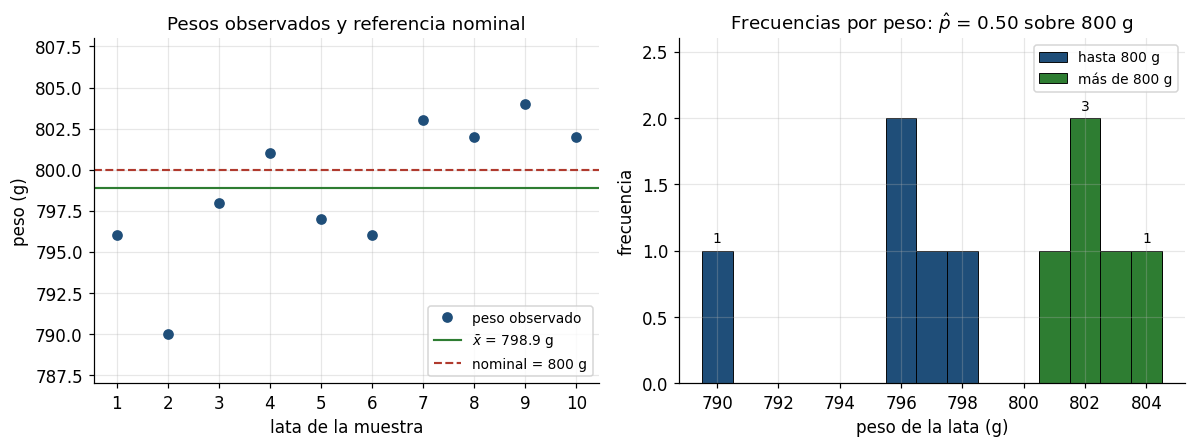

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

axs[0].plot(range(1, n + 1), latas, "o", color=AZUL, label="peso observado")
axs[0].axhline(xbar, color=VERDE, linewidth=1.4, label=r"$\bar{x}$ = 798.9 g")
axs[0].axhline(800, color=ROJO, linewidth=1.4, linestyle="--", label="nominal = 800 g")
axs[0].set_xticks(range(1, n + 1))
axs[0].set_xlabel("lata de la muestra")
axs[0].set_ylabel("peso (g)")
axs[0].set_ylim(787, 808)
axs[0].set_title("Pesos observados y referencia nominal")
axs[0].legend(fontsize=9, loc="lower right")

bins = np.arange(789.5, 805.5, 1)
axs[1].hist(latas, bins=bins, color=AZUL, edgecolor="black", linewidth=0.6,
            label="hasta 800 g")
axs[1].hist(latas[sobre_800], bins=bins, color=VERDE, edgecolor="black", linewidth=0.6,
            label="más de 800 g")
for marca in (790, 804):
    axs[1].text(marca, 1.06, "1", ha="center", fontsize=9)
axs[1].text(802, 2.06, "3", ha="center", fontsize=9)
axs[1].set_xticks(np.arange(790, 805, 2))
axs[1].set_xlabel("peso de la lata (g)")
axs[1].set_ylabel("frecuencia")
axs[1].set_ylim(0, 2.6)
axs[1].set_title(r"Frecuencias por peso: $\hat{p}$ = 0.50 sobre 800 g")
axs[1].legend(fontsize=9)

plt.tight_layout()
plt.show()


### b) Estimadores insesgados

El inciso a) arroja cuatro números, pero cada uno proviene de un estimador con propiedades distintas.
Para decidir el insesgamiento se aplica $E[T] = \theta$ a cada fórmula, usando linealidad del valor
esperado, independencia de las observaciones y $E[X_i] = \mu$, $\operatorname{Var}(X_i) = \sigma^2$:

| Parámetro | Estimador usado | $E[T]$ | ¿Insesgado? |
|---|---|---|---|
| $\mu$ | $\bar X$ | $\mu$ | sí |
| $\sigma^2$ | $S^2$ (denominador $n-1$) | $\sigma^2$ | sí |
| $\sigma$ | $S = \sqrt{S^2}$ | $E[S] < \sigma$ | no |
| $p$ | $\hat p$ | $p$ | sí |

**Media muestral.** Por linealidad del valor esperado, sin necesidad de suponer normalidad:

$$E[\bar X] = E\left[\frac{1}{n}\sum_{i=1}^{n} X_i\right] = \frac{1}{n}\sum_{i=1}^{n} E[X_i] = \frac{1}{n}\cdot n\mu = \mu$$

**Varianza muestral.** Se parte de la identidad $\sum (X_i - \bar X)^2 = \sum (X_i - \mu)^2 - n(\bar X - \mu)^2$.
Al tomar esperanzas, $E\left[\sum (X_i - \mu)^2\right] = n\sigma^2$ y
$E\left[n(\bar X - \mu)^2\right] = n \cdot \dfrac{\sigma^2}{n} = \sigma^2$, de donde
$E\left[\sum (X_i - \bar X)^2\right] = (n-1)\sigma^2$ y por lo tanto

$$E[S^2] = \frac{(n-1)\sigma^2}{n-1} = \sigma^2$$

Con denominador $n$ el estimador quedaría sesgado hacia abajo, con $E[B_2] = \frac{n-1}{n}\sigma^2$ y
sesgo $-\sigma^2/n$. Por eso la variabilidad cuadrática promedio se estima con $n - 1$: la corrección
compensa que la suma de cuadrados se calcule respecto de $\bar X$ y no respecto del $\mu$ desconocido,
lo que le roba un grado de libertad.

**Desviación estándar.** La raíz cuadrada es cóncava, luego la desigualdad de Jensen con
$E[S^2] = \sigma^2$ conduce a

$$E[S] = E[\sqrt{S^2}] \le \sqrt{E[S^2]} = \sigma$$

y la desigualdad es estricta mientras $\operatorname{Var}(S^2) > 0$. El sesgo es negativo: $s$
subestima $\sigma$ de forma sistemática, el déficit solo se anula cuando $n \to \infty$ (por
continuidad de la raíz y consistencia de $S^2$) y en muestras pequeñas puede ser apreciable.

**Proporción.** $\hat p$ es la media muestral de las indicadoras $y_i$, con $E[y_i] = p$ y
$\operatorname{Var}(y_i) = p(1-p)$, de donde

$$E[\hat p] = p, \qquad \operatorname{Var}(\hat p) = \frac{p(1-p)}{n}$$

El insesgamiento es una propiedad de la fórmula del estimador, no del número puntual que produce una
muestra concreta: $\bar x = 798.9$ g no es "insesgado", lo es el estimador $\bar X$ para cualquier
muestra. La verificación siguiente estima por simulación los valores esperados de los cuatro
estimadores, usando la normal ajustada a la propia muestra como población de referencia.

In [4]:
# simulacion Monte Carlo: valores esperados de los estimadores del inciso a)
rng = np.random.default_rng(21)
ensayos = 100_000

mu_ref, sigma_ref = xbar, s          # la muestra se toma como referencia poblacional
p_ref = p_hat
simuladas = rng.normal(mu_ref, sigma_ref, size=(ensayos, n))

media_sim = simuladas.mean(axis=1)
var_sim = simuladas.var(axis=1, ddof=1)
sd_sim = np.sqrt(var_sim)
p_sim = rng.binomial(n, p_ref, ensayos) / n

registros = [
    ("media muestral",   media_sim.mean(), mu_ref,       media_sim.std(ddof=1)),
    ("varianza muestral", var_sim.mean(),  sigma_ref**2, var_sim.std(ddof=1)),
    ("desv. estándar",   sd_sim.mean(),    sigma_ref,    sd_sim.std(ddof=1)),
    ("proporcion",       p_sim.mean(),     p_ref,        p_sim.std(ddof=1)),
]

print(f"población de referencia: mu = {mu_ref:.4f} g, sigma^2 = {sigma_ref**2:.4f} g^2, p = {p_ref:.4f}")
print(f"ensayos Monte Carlo: {ensayos:,}")
print()
print(f"{'estimador':<19}{'E[T] simulado':>15}{'parametro':>12}{'error est.':>12}")
print("-" * 58)
for nombre, est, teo, sd_est in registros:
    ee = sd_est / math.sqrt(ensayos)
    print(f"{nombre:<19}{est:>15.4f}{teo:>12.4f}{ee:>12.4f}")

print()
print(f"la media simulada de la desv. estándar queda {sigma_ref - sd_sim.mean():.4f} g por debajo")
print(f"de sigma, con un error estándar de {sd_sim.std(ddof=1) / math.sqrt(ensayos):.4f} g: el sesgo")
print("negativo de S es sistemático y no un artefacto del tamaño de la simulación")


población de referencia: mu = 798.9000 g, sigma^2 = 18.5444 g^2, p = 0.5000
ensayos Monte Carlo: 100,000

estimador            E[T] simulado   parametro  error est.
----------------------------------------------------------
media muestral            798.8968    798.9000      0.0043
varianza muestral          18.5411     18.5444      0.0276
desv. estándar              4.1886      4.3063      0.0032
proporcion                  0.5010      0.5000      0.0005

la media simulada de la desv. estándar queda 0.1177 g por debajo
de sigma, con un error estándar de 0.0032 g: el sesgo
negativo de S es sistemático y no un artefacto del tamaño de la simulación


## 2. Propiedades de la media muestral en una normal

Sea $X_1, X_2, \dots, X_n$ una muestra aleatoria de una población $N(\mu, \sigma^2)$ con $\mu$ y
$\sigma^2$ desconocidos. Las observaciones son independientes, con $E[X_i] = \mu$ y
$\operatorname{Var}(X_i) = \sigma^2$ para todo $i$.

### a) La media muestral es insesgada para $\mu$

Aplicando linealidad del valor esperado, como en el inciso 1.b,

$$E[\bar X] = E\left[\frac{1}{n}\sum_{i=1}^{n} X_i\right] = \frac{1}{n}\sum_{i=1}^{n} E[X_i] = \frac{1}{n}\cdot n\mu = \mu$$

El resultado no usa la normalidad: vale para cualquier distribución con media finita. La normalidad
aporta la forma de la distribución muestral: $\bar X$ es exactamente $N(\mu, \sigma^2/n)$ y, por el
teorema del límite central, es asintóticamente normal aunque la población no lo sea.

### b) Varianza de la media muestral

Por independencia de las observaciones, los términos cruzados de la varianza se anulan:

$$\operatorname{Var}(\bar X) = \operatorname{Var}\left(\frac{1}{n}\sum_{i=1}^{n} X_i\right) = \frac{1}{n^2}\sum_{i=1}^{n} \operatorname{Var}(X_i) = \frac{n\sigma^2}{n^2} = \frac{\sigma^2}{n}$$

La varianza del estimador decae como $1/n$. La consecuencia práctica es que la precisión crece con la
raíz del tamaño de muestra: reducir a la mitad la dispersión de $\bar X$ exige duplicar $n$, y pasar
de $n = 10$ a $n = 100$ solo reduce la varianza diez veces. Ningún tamaño finito de muestra hace cero
la varianza del estimador.

### c) $\bar X^2$ no es insesgado para $\mu^2$

El estimador propuesto para $\mu^2$ es el cuadrado de la media muestral. Descomponiendo la varianza,

$$E[\bar X^2] = \operatorname{Var}(\bar X) + \left(E[\bar X]\right)^2 = \frac{\sigma^2}{n} + \mu^2$$

que no coincide con $\mu^2$ para $n$ finito. Luego $\bar X^2$ es un estimador **sesgado** de $\mu^2$,
con sesgo $\sigma^2/n > 0$: el sesgo es siempre positivo porque $E[\bar X^2] \ge (E[\bar X])^2$ y se
anula solo en el límite $n \to \infty$. Un estimador insesgado se obtiene restando la estimación de la
varianza de $\bar X$ dividida por $n$:

$$T = \bar X^2 - \frac{S^2}{n}, \qquad E[T] = \mu^2 + \frac{\sigma^2}{n} - \frac{\sigma^2}{n} = \mu^2$$

El inciso c) ilustra que el insesgamiento no se hereda por operaciones no lineales: $\bar X$ es
insesgado para $\mu$, pero su cuadrado no lo es para $\mu^2$, porque el valor esperado de un producto
no es el producto de los valores esperados ni el cuadrado del esperado.

In [5]:
# verificación numérica con mu = 100 y sigma = 15
rng = np.random.default_rng(5)
mu, sigma = 100.0, 15.0
ensayos = 100_000
tamanios = [5, 10, 25, 50, 100]

var_empirica, sesgo_empirico = [], []

print(f"{'n':>5}{'E[Xbar]':>11}{'Var(Xbar)':>12}{'sigma^2/n':>12}"
      f"{'E[Xbar^2]-mu^2':>17}{'sesgo teórico':>15}")
print("-" * 73)
for n_ in tamanios:
    medias = rng.normal(mu, sigma, size=(ensayos, n_)).mean(axis=1)
    var_empirica.append(medias.var(ddof=1))
    # sesgo de Xbar^2: por la identidad Xbar^2 - mu^2 = (Xbar - mu)^2 + 2 mu (Xbar - mu) y
    # E[Xbar - mu] = 0, el sesgo se estima como la media de (Xbar - mu)^2; su varianza es
    # 2(sigma^2/n)^2, sin el termino 4 mu^2 sigma^2/n que arrastra el estimador directo
    sesgo_empirico.append(((medias - mu) ** 2).mean())
    print(f"{n_:>5}{medias.mean():>11.3f}{medias.var(ddof=1):>12.3f}{sigma**2 / n_:>12.3f}"
          f"{sesgo_empirico[-1]:>17.3f}{sigma**2 / n_:>15.3f}")

print()
print(f"mu = {mu}, sigma^2 = {sigma**2}, ensayos = {ensayos:,}")
print("E[Xbar] converge a mu y Var(Xbar) a sigma^2/n; el sesgo de Xbar^2 sigue la misma ley 1/n")


    n    E[Xbar]   Var(Xbar)   sigma^2/n   E[Xbar^2]-mu^2  sesgo teórico
-------------------------------------------------------------------------
    5    100.013      44.880      45.000           44.880         45.000
   10    100.019      22.576      22.500           22.576         22.500
   25     99.968       9.057       9.000            9.058          9.000
   50     99.993       4.513       4.500            4.513          4.500


  100    100.005       2.249       2.250            2.249          2.250

mu = 100.0, sigma^2 = 225.0, ensayos = 100,000
E[Xbar] converge a mu y Var(Xbar) a sigma^2/n; el sesgo de Xbar^2 sigue la misma ley 1/n


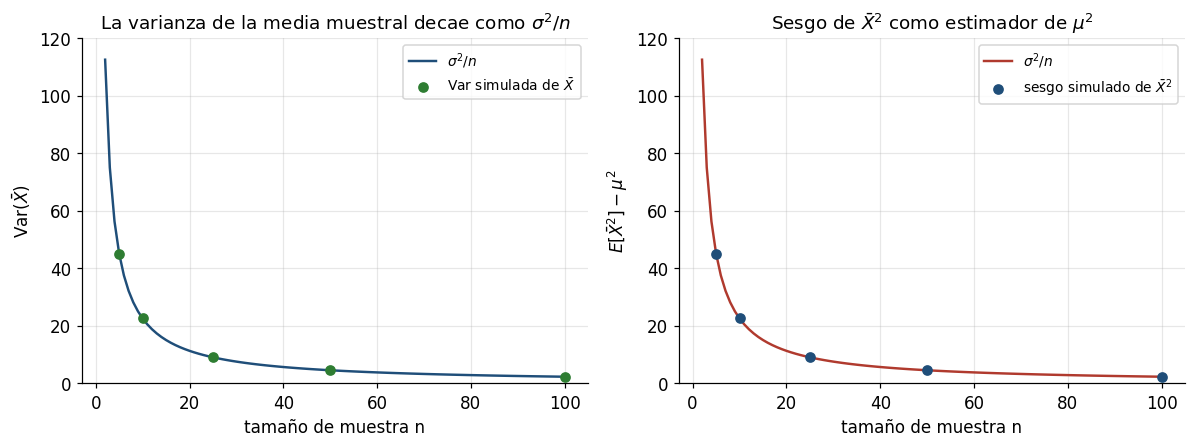

In [6]:
grilla = np.arange(2, 101)
teorica = sigma ** 2 / grilla

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

axs[0].plot(grilla, teorica, color=AZUL, linewidth=1.6, label=r"$\sigma^2/n$")
axs[0].scatter(tamanios, var_empirica, color=VERDE, zorder=5, label="Var simulada de $\\bar{X}$")
axs[0].set_xlabel("tamaño de muestra n")
axs[0].set_ylabel(r"$\operatorname{Var}(\bar{X})$")
axs[0].set_ylim(0, 120)
axs[0].set_title("La varianza de la media muestral decae como $\\sigma^2/n$")
axs[0].legend(fontsize=9)

axs[1].plot(grilla, teorica, color=ROJO, linewidth=1.6, label=r"$\sigma^2/n$")
axs[1].scatter(tamanios, sesgo_empirico, color=AZUL, zorder=5,
               label=r"sesgo simulado de $\bar{X}^2$")
axs[1].set_xlabel("tamaño de muestra n")
axs[1].set_ylabel(r"$E[\bar{X}^2] - \mu^2$")
axs[1].set_ylim(0, 120)
axs[1].set_title(r"Sesgo de $\bar{X}^2$ como estimador de $\mu^2$")
axs[1].legend(fontsize=9)

plt.tight_layout()
plt.show()


## 3. Dos estimadores ponderados de la media

Se dispone de una muestra aleatoria de tamaño dos, $X_1, X_2$, de una población de media $\mu$ y
varianza $\sigma^2$, y se plantean dos estimadores puntuales de $\mu$ como promedios ponderados:

$$\hat\mu_a = \frac{1}{3}X_1 + \frac{2}{3}X_2, \qquad \hat\mu_b = \frac{1}{4}X_1 + \frac{3}{4}X_2$$

### a.1) ¿Cuál es insesgado para estimar $\mu$?

En general, para un promedio ponderado $\hat\mu = w_1 X_1 + w_2 X_2$ con pesos que suman uno,

$$E[\hat\mu] = w_1 E[X_1] + w_2 E[X_2] = (w_1 + w_2)\mu = \mu$$

el valor esperado es $\mu$ cualquiera sea la distribución de la población y con independencia o no
entre observaciones. Ambos estimadores cumplen la condición: $\frac{1}{3} + \frac{2}{3} = 1$ y
$\frac{1}{4} + \frac{3}{4} = 1$, de modo que **los dos son insesgados**. La desigualdad de los pesos no
rompe el insesgamiento, porque no altera el valor esperado; lo que altera es la varianza, que es el
criterio de desempate.

### a.2) ¿Cuál tiene la menor varianza?

Con observaciones independientes, la varianza del promedio ponderado es

$$\operatorname{Var}(\hat\mu) = w_1^2\operatorname{Var}(X_1) + w_2^2\operatorname{Var}(X_2) = \left(w_1^2 + w_2^2\right)\sigma^2$$

Aplicando a cada estimador:

$$\operatorname{Var}(\hat\mu_a) = \left(\frac{1}{9} + \frac{4}{9}\right)\sigma^2 = \frac{5}{9}\sigma^2 \approx 0.5556\,\sigma^2$$

$$\operatorname{Var}(\hat\mu_b) = \left(\frac{1}{16} + \frac{9}{16}\right)\sigma^2 = \frac{10}{16}\sigma^2 = \frac{5}{8}\sigma^2 = 0.6250\,\sigma^2$$

$\hat\mu_a$ tiene la menor varianza. El criterio es el coeficiente $w_1^2 + w_2^2$: al ser la suma de
cuadrados con la restricción $w_1 + w_2 = 1$, se minimiza repartiendo el peso por igual, con
$w_1 = w_2 = 1/2$ y varianza $\sigma^2/2$ (la media muestral de dos observaciones). Cuanto más se
desvían los pesos de esa igualdad, más se concentra el peso en una sola observación y mayor es la
varianza: $\hat\mu_b$ apoya tres cuartas partes de su peso en $X_2$ y por eso es el más variable de
los dos.

### b) Eficiencia relativa de $\hat\mu_a$ con respecto de $\hat\mu_b$

Como ambos son insesgados, la comparación de varianzas es equivalente a la de errores cuadráticos
medios. La eficiencia relativa es el cociente inverso de las varianzas:

$$\operatorname{EFF}(\hat\mu_a, \hat\mu_b) = \frac{\operatorname{Var}(\hat\mu_b)}{\operatorname{Var}(\hat\mu_a)} = \frac{5/8}{5/9} = \frac{9}{8} = 1.125$$

Como es mayor que uno, $\hat\mu_a$ es el más eficiente. La lectura en tamaño de muestra equivalente:
para igualar la varianza de $\hat\mu_b$, $\hat\mu_a$ alcanza con
$n_1 = n_2/1.125 = 0.889\,n_2$ observaciones, es decir un 11.1% menos de muestras; recíprocamente,
$\hat\mu_b$ necesitaría 12.5% más de observaciones para lograr la misma dispersión. Ninguno de los dos
es eficiente en sentido estricto: con dos observaciones, el mínimo varianza insesgado es
$\bar X = \frac{1}{2}X_1 + \frac{1}{2}X_2$, con varianza $0.5\,\sigma^2$, menor que ambas.

In [7]:
w_a = np.array([1 / 3, 2 / 3])
w_b = np.array([1 / 4, 3 / 4])

var_a = (w_a ** 2).sum()          # coeficiente de sigma^2
var_b = (w_b ** 2).sum()
eff_ab = var_b / var_a

print(f"pesos de Xa: {w_a[0]:.4f} + {w_a[1]:.4f} = {w_a.sum():.4f}  -> E[Xa] = mu, insesgado")
print(f"pesos de Xb: {w_b[0]:.4f} + {w_b[1]:.4f} = {w_b.sum():.4f}  -> E[Xb] = mu, insesgado")
print()
print(f"Var(Xa) = ({w_a[0]**2:.4f} + {w_a[1]**2:.4f}) sigma^2 = {var_a:.4f} sigma^2 = 5/9 sigma^2")
print(f"Var(Xb) = ({w_b[0]**2:.4f} + {w_b[1]**2:.4f}) sigma^2 = {var_b:.4f} sigma^2 = 5/8 sigma^2")
print(f"media muestral (pesos 1/2, 1/2): {(0.5**2 + 0.5**2):.4f} sigma^2  -> mínimo insesgado")
print()
print(f"EFF(Xa, Xb) = Var(Xb)/Var(Xa) = {eff_ab:.6f} = 9/8 = 1.125")
print(f"Xb requiere {eff_ab:.4f} veces más observaciones; Xa alcanza con {1 / eff_ab * 100:.1f}% menos")


pesos de Xa: 0.3333 + 0.6667 = 1.0000  -> E[Xa] = mu, insesgado
pesos de Xb: 0.2500 + 0.7500 = 1.0000  -> E[Xb] = mu, insesgado

Var(Xa) = (0.1111 + 0.4444) sigma^2 = 0.5556 sigma^2 = 5/9 sigma^2
Var(Xb) = (0.0625 + 0.5625) sigma^2 = 0.6250 sigma^2 = 5/8 sigma^2
media muestral (pesos 1/2, 1/2): 0.5000 sigma^2  -> mínimo insesgado

EFF(Xa, Xb) = Var(Xb)/Var(Xa) = 1.125000 = 9/8 = 1.125
Xb requiere 1.1250 veces más observaciones; Xa alcanza con 88.9% menos


In [8]:
# verificación por simulación con mu = 50 y sigma = 8
rng = np.random.default_rng(3)
muestras = 200_000
mu, sigma = 50.0, 8.0

x1 = rng.normal(mu, sigma, muestras)
x2 = rng.normal(mu, sigma, muestras)
xa = w_a[0] * x1 + w_a[1] * x2
xb = w_b[0] * x1 + w_b[1] * x2
xm = 0.5 * (x1 + x2)

print(f"población de referencia: mu = {mu}, sigma^2 = {sigma**2}")
print(f"{'estimador':<22}{'media simulada':>15}{'var/sigma^2':>13}{'var/sigma^2 teórica':>21}")
print("-" * 71)
for nombre, valores, teorico in [("Xa = 1/3 X1 + 2/3 X2", xa, 5 / 9),
                                 ("Xb = 1/4 X1 + 3/4 X2", xb, 5 / 8),
                                 ("media muestral", xm, 1 / 2)]:
    print(f"{nombre:<22}{valores.mean():>15.4f}{valores.var(ddof=1) / sigma**2:>13.4f}{teorico:>21.4f}")

eff_sim = xb.var(ddof=1) / xa.var(ddof=1)
print()
print(f"eficiencia relativa simulada: {eff_sim:.4f}  (teórica 9/8 = 1.1250)")


población de referencia: mu = 50.0, sigma^2 = 64.0
estimador              media simulada  var/sigma^2  var/sigma^2 teórica
-----------------------------------------------------------------------
Xa = 1/3 X1 + 2/3 X2          50.0134       0.5580               0.5556
Xb = 1/4 X1 + 3/4 X2          50.0146       0.6278               0.6250
media muestral                50.0109       0.5017               0.5000

eficiencia relativa simulada: 1.1250  (teórica 9/8 = 1.1250)


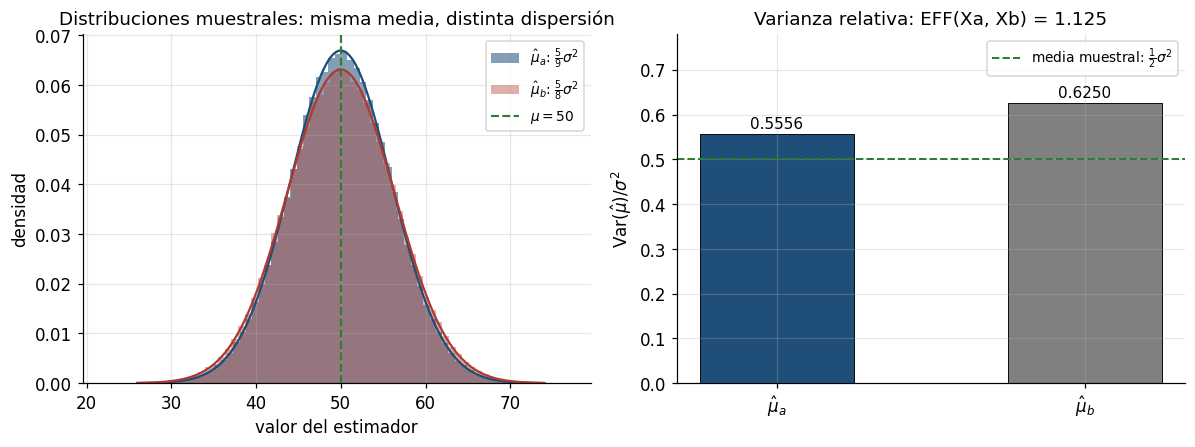

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

t = np.linspace(mu - 24, mu + 24, 400)


def densidad_normal(valores, media):
    """Densa de N(media, sigma^2 del estimador) evaluada en t."""
    sd = sigma * math.sqrt(valores)
    return np.exp(-0.5 * ((t - media) / sd) ** 2) / (sd * math.sqrt(2 * math.pi))


axs[0].hist(xa, bins=70, density=True, color=AZUL, alpha=0.55, edgecolor="none",
            label=r"$\hat\mu_a$: $\frac{5}{9}\sigma^2$")
axs[0].hist(xb, bins=70, density=True, color=ROJO, alpha=0.40, edgecolor="none",
            label=r"$\hat\mu_b$: $\frac{5}{8}\sigma^2$")
axs[0].plot(t, densidad_normal(var_a, mu), color=AZUL, linewidth=1.5)
axs[0].plot(t, densidad_normal(var_b, mu), color=ROJO, linewidth=1.5)
axs[0].axvline(mu, color=VERDE, linewidth=1.4, linestyle="--", label=r"$\mu = 50$")
axs[0].set_xlabel("valor del estimador")
axs[0].set_ylabel("densidad")
axs[0].set_title("Distribuciones muestrales: misma media, distinta dispersión")
axs[0].legend(fontsize=9)

barras = axs[1].bar([0, 1], [var_a, var_b], width=0.5, color=[AZUL, GRIS],
                    edgecolor="black", linewidth=0.6)
axs[1].axhline(0.5, color=VERDE, linestyle="--", linewidth=1.3,
               label=r"media muestral: $\frac{1}{2}\sigma^2$")
for rect, valor in zip(barras, [var_a, var_b]):
    axs[1].text(rect.get_x() + rect.get_width() / 2, valor + 0.014, f"{valor:.4f}",
                ha="center", fontsize=10)
axs[1].set_xticks([0, 1], [r"$\hat\mu_a$", r"$\hat\mu_b$"])
axs[1].set_ylabel(r"$\operatorname{Var}(\hat\mu)/\sigma^2$")
axs[1].set_ylim(0, 0.78)
axs[1].set_title(f"Varianza relativa: EFF(Xa, Xb) = {eff_ab:.3f}")
axs[1].legend(fontsize=9, loc="upper right")

plt.tight_layout()
plt.show()


## 4. Contador de partículas: EMV de $\lambda$ en una Poisson

El número de partículas radiactivas que atraviesan un contador en un milisegundo se modela como
$X \sim \text{Poisson}(\lambda)$, con $\lambda$ desconocido. La masa de probabilidad es

$$P(X = x) = \frac{e^{-\lambda}\lambda^{x}}{x!}, \qquad x = 0, 1, 2, \dots$$

con $E[X] = \operatorname{Var}(X) = \lambda$. Se registran los conteos de $n = 5$ intervalos
consecutivos de un milisegundo:

| intervalo | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| $x_i$ | 0 | 3 | 4 | 5 | 1 |

El muestreo por intervalos fijos e independientes habilita el modelo: el conteo de un intervalo no
condiciona al del siguiente y todos comparten la misma $\lambda$.

### a) Función de verosimilitud

Por independencia, la verosimilitud es el producto de las masas evaluadas en los conteos observados.
Agrupando los factores según aparezcan en el numerador o el denominador,

$$L(\lambda) = \prod_{i=1}^{5} \frac{e^{-\lambda}\lambda^{x_i}}{x_i!} = \frac{e^{-5\lambda}\,\lambda^{\sum x_i}}{\prod_{i=1}^{5} x_i!} = \frac{1}{0!\,3!\,4!\,5!\,1!}\,e^{-5\lambda}\lambda^{13} = \frac{1}{17280}\,e^{-5\lambda}\lambda^{13}$$

ya que $\sum x_i = 0 + 3 + 4 + 5 + 1 = 13$. El factor $1/17280$ no depende de $\lambda$: es una
constante de la muestra y no desplaza el máximo de la verosimilitud, pero sí fija su escala.

### b) Estimador máximo verosímil de $\lambda$

Se maximiza el logaritmo, que convierte el producto en suma y al producto de potencias en expresión
lineal:

$$\ell(\lambda) = \ln L(\lambda) = -5\lambda + 13\ln\lambda - \ln 17280$$

Ecuación de verosimilitad:

$$\frac{d\ell}{d\lambda} = -5 + \frac{13}{\lambda} = 0 \quad \Longrightarrow \quad \hat\lambda = \frac{13}{5} = 2.6$$

La segunda derivada $\ell''(\lambda) = -13/\lambda^2$ es negativa para todo $\lambda > 0$, de modo que
el logaritmo es estrictamente cóncavo en el soporte del parámetro y el punto estacionario es un máximo
global. La verosimilitud tiende a cero cuando $\lambda \to 0^+$ y cuando $\lambda \to \infty$, lo que
confirma que no hay máximos en el borde.

El resultado se generaliza para cualquier muestra de una Poisson: la ecuación de verosimilitud
$-n + \left(\sum x_i\right)/\lambda = 0$ conduce a

$$\hat\lambda = \frac{\sum_{i=1}^{n} x_i}{n} = \bar x$$

El EMV de $\lambda$ es la media muestral de los conteos, que además es insesgada para el parámetro y
consistente. En este caso la estimación es $\hat\lambda = 2.6$ partículas por milisegundo.

In [10]:
conteos = np.array([0, 3, 4, 5, 1])
n_conteos = conteos.size
suma_conteos = conteos.sum()
constante = sum(math.log(math.factorial(int(v))) for v in conteos)


def log_verosimilitud_poisson(lam, x):
    """Log-verosimilitud de una Poisson; lam puede ser escalar o array."""
    lam = np.asarray(lam, dtype=float)
    return -x.size * lam + x.sum() * np.log(lam) - constante


def score_poisson(lam, x):
    """Funcion score: derivada del log-verosimilitud respecto de lambda."""
    return -x.size + x.sum() / lam


denominador = math.factorial(0) * math.factorial(3) * math.factorial(4) * math.factorial(5)

print("conteos observados:", conteos.tolist())
print(f"suma de conteos = {suma_conteos}, n = {n_conteos}")
print(f"L(lam) = e^(-5 lam) lam^13 / {denominador}  con 0!3!4!5!1! = {denominador}")
print()
print(f"EMV por la ecuación de verosimilitud: lambda = {suma_conteos}/{n_conteos} = {suma_conteos / n_conteos:.4f}")
print(f"score en el EMV: {score_poisson(suma_conteos / n_conteos, conteos):.3e}")
print(f"segunda derivada en el EMV: {-suma_conteos / (suma_conteos / n_conteos)**2:.4f} < 0")
print(f"log-verosimilitud en el EMV: {log_verosimilitud_poisson(suma_conteos / n_conteos, conteos):.4f}")

# contraste con una búsqueda directa sobre una grilla fina
grilla = np.linspace(0.05, 6, 20000)
lam_grilla = grilla[np.argmax(log_verosimilitud_poisson(grilla, conteos))]
print(f"EMV por búsqueda en grilla (20000 puntos): lambda = {lam_grilla:.4f}")


conteos observados: [0, 3, 4, 5, 1]
suma de conteos = 13, n = 5
L(lam) = e^(-5 lam) lam^13 / 17280  con 0!3!4!5!1! = 17280

EMV por la ecuación de verosimilitud: lambda = 13/5 = 2.6000
score en el EMV: 0.000e+00
segunda derivada en el EMV: -1.9231 < 0
log-verosimilitud en el EMV: -10.3357
EMV por búsqueda en grilla (20000 puntos): lambda = 2.6000


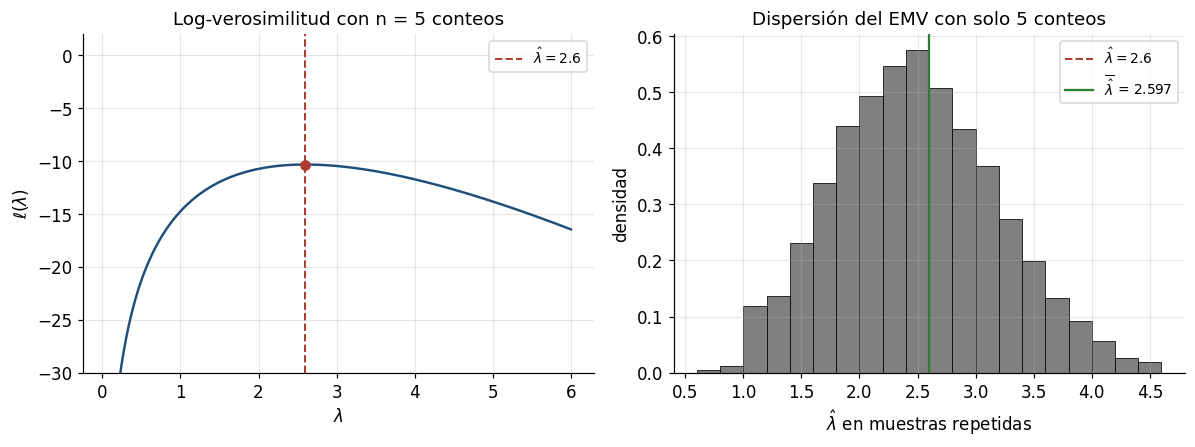

desv. estándar teórica del EMV: sqrt(lambda/n) = 0.7211
desv. estándar simulada:        0.7220
sesgo simulado:                 -0.0034
con n = 5 el EMV solo toma múltiplos de 1/5: la distribución muestral es discreta y muy amplia


In [11]:
lam_mle = suma_conteos / n_conteos
lam_eval = np.linspace(0.05, 6, 400)
ell = log_verosimilitud_poisson(lam_eval, conteos)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

axs[0].plot(lam_eval, ell, color=AZUL, linewidth=1.6)
axs[0].axvline(lam_mle, color=ROJO, linestyle="--", linewidth=1.3,
               label=r"$\hat\lambda = 2.6$")
axs[0].plot(lam_mle, log_verosimilitud_poisson(lam_mle, conteos), "o", color=ROJO)
axs[0].set_xlabel(r"$\lambda$")
axs[0].set_ylabel(r"$\ell(\lambda)$")
axs[0].set_ylim(-30, 2)
axs[0].set_title("Log-verosimilitud con n = 5 conteos")
axs[0].legend(fontsize=9)

# muestras repetidas del mismo experimento: dispersion del EMV
rng = np.random.default_rng(13)
muestras = 20_000
conteos_sim = rng.poisson(lam_mle, size=(muestras, n_conteos))
lam_sim = conteos_sim.mean(axis=1)

axs[1].hist(lam_sim, bins=np.arange(0.6, 4.65, 0.2), color=GRIS, edgecolor="black",
            linewidth=0.5, density=True)
axs[1].axvline(lam_mle, color=ROJO, linestyle="--", linewidth=1.3, label=r"$\hat\lambda = 2.6$")
axs[1].axvline(lam_sim.mean(), color=VERDE, linewidth=1.5,
               label=rf"$\overline{{\hat\lambda}}$ = {lam_sim.mean():.3f}")
axs[1].set_xlabel(r"$\hat\lambda$ en muestras repetidas")
axs[1].set_ylabel("densidad")
axs[1].set_title("Dispersión del EMV con solo 5 conteos")
axs[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

print(f"desv. estándar teórica del EMV: sqrt(lambda/n) = {math.sqrt(lam_mle / n_conteos):.4f}")
print(f"desv. estándar simulada:        {lam_sim.std(ddof=1):.4f}")
print(f"sesgo simulado:                 {lam_sim.mean() - lam_mle:+.4f}")
print("con n = 5 el EMV solo toma múltiplos de 1/5: la distribución muestral es discreta y muy amplia")


## 5. Experimento binomial: EMV de $p$

En un experimento binomial se observan $x = 5$ éxitos en $n$ ensayos independientes, cada uno con
probabilidad de éxito $p$ desconocida. El número de éxitos tiene masa

$$P(X = x) = C(n,x)\, p^{x}(1-p)^{n-x}, \qquad x = 0, 1, \dots, n$$

Aquí $x = 5$ es el dato observado y $n$ fija el soporte del parámetro, $0 \le p \le 1$. Tratando a $p$
como incógnita, la verosimilitud es

$$L(p) = C(n,5)\, p^{5}(1-p)^{n-5}$$

y su logaritmo, con el coeficiente binomial reducido a una constante aditiva:

$$\ell(p) = \ln C(n,5) + 5\ln p + (n-5)\ln(1-p)$$

Ecuación de verosimilitad:

$$\frac{d\ell}{dp} = \frac{5}{p} - \frac{n-5}{1-p} = 0 \quad \Longrightarrow \quad 5(1-p) = (n-5)p \quad \Longrightarrow \quad 5 = np$$

$$\hat p = \frac{5}{n}$$

La segunda derivada, $\ell''(p) = -\dfrac{5}{p^2} - \dfrac{n-5}{(1-p)^2}$, es negativa en todo el
interior del soporte, por lo que $\ell$ es estrictamente cóncava y $\hat p$ es el máximo global. En
los extremos $p = 0$ o $p = 1$ la verosimilitud se anula porque la muestra contiene éxitos y también
fracasos; una muestra de éxitos puros daría EMV en el borde.

En general, con $x$ éxitos en $n$ ensayos, el EMV es la proporción muestral:

$$\hat p = \frac{x}{n}$$

que coincide con la media muestral de las indicadoras de éxito, con $E[\hat p] = p$ y
$\operatorname{Var}(\hat p) = p(1-p)/n$: el EMV es a la vez insesgado y consistente. El parámetro
depende de la razón éxitos/ensayos y no del número de éxitos aisladamente: con los mismos 5 éxitos, un
experimento de $n = 20$ ensayos conduce a $\hat p = 0.25$ y uno de $n = 50$ a $\hat p = 0.10$, que
corresponden a hipótesis muy distintas sobre la probabilidad de éxito.

In [12]:
def log_verosimilitud_binomial(p, x, n_ensayos):
    """Log-verosimilitud de una binomial en funcion de p."""
    p = np.asarray(p, dtype=float)
    return np.log(math.comb(n_ensayos, x)) + x * np.log(p) + (n_ensayos - x) * np.log1p(-p)


grilla_p = np.linspace(0.001, 0.999, 20000)

for n_ensayos, x_ in [(20, 5), (50, 5)]:
    p_mle = x_ / n_ensayos
    p_grilla = grilla_p[np.argmax(log_verosimilitud_binomial(grilla_p, x_, n_ensayos))]
    score = x_ / p_mle - (n_ensayos - x_) / (1 - p_mle)
    segunda = -(x_ / p_mle**2) - ((n_ensayos - x_) / (1 - p_mle)**2)
    print(f"n = {n_ensayos:2d} ensayos, éxitos = {x_}:")
    print(f"   EMV por la ecuación de verosimilitud: p = {x_}/{n_ensayos} = {p_mle:.4f}")
    print(f"   EMV por búsqueda en grilla:           p = {p_grilla:.4f}")
    print(f"   score(p_hat) = {score:.3e} | ell''(p_hat) = {segunda:.4f} < 0")
    print(f"   log-verosimilitud en el EMV: {log_verosimilitud_binomial(p_mle, x_, n_ensayos):.4f}")
    print()

# el caso general: con x éxitos en n ensayos el EMV es siempre x/n
x_prueba, n_prueba = 17, 60
print(f"verificación general: x = {x_prueba}, n = {n_prueba} -> p_hat = {x_prueba}/{n_prueba} = "
      f"{grilla_p[np.argmax(log_verosimilitud_binomial(grilla_p, x_prueba, n_prueba))]:.4f}")


n = 20 ensayos, éxitos = 5:
   EMV por la ecuación de verosimilitud: p = 5/20 = 0.2500
   EMV por búsqueda en grilla:           p = 0.2500
   score(p_hat) = 0.000e+00 | ell''(p_hat) = -106.6667 < 0
   log-verosimilitud en el EMV: -1.5978

n = 50 ensayos, éxitos = 5:
   EMV por la ecuación de verosimilitud: p = 5/50 = 0.1000
   EMV por búsqueda en grilla:           p = 0.1000
   score(p_hat) = 0.000e+00 | ell''(p_hat) = -555.5556 < 0
   log-verosimilitud en el EMV: -1.6878

verificación general: x = 17, n = 60 -> p_hat = 17/60 = 0.2833


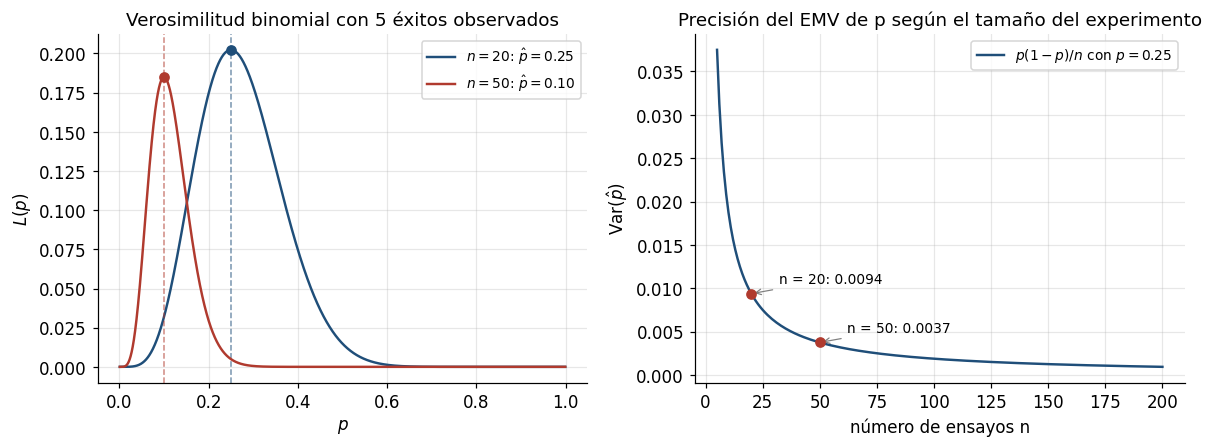

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

for n_ensayos, x_, color in [(20, 5, AZUL), (50, 5, ROJO)]:
    L = np.exp(log_verosimilitud_binomial(grilla_p, x_, n_ensayos))
    p_mle = x_ / n_ensayos
    axs[0].plot(grilla_p, L, color=color, linewidth=1.6,
                label=rf"$n = {n_ensayos}$: $\hat p = {p_mle:.2f}$")
    axs[0].plot(p_mle, np.exp(log_verosimilitud_binomial(p_mle, x_, n_ensayos)), "o", color=color)
    axs[0].axvline(p_mle, color=color, linestyle="--", linewidth=1.0, alpha=0.6)
axs[0].set_xlabel(r"$p$")
axs[0].set_ylabel(r"$L(p)$")
axs[0].set_title("Verosimilitud binomial con 5 éxitos observados")
axs[0].legend(fontsize=9)

n_var = np.arange(5, 201)
p_ref = 0.25
var_p = p_ref * (1 - p_ref) / n_var

axs[1].plot(n_var, var_p, color=AZUL, linewidth=1.6, label=r"$p(1-p)/n$ con $p = 0.25$")
for n_marcado in (20, 50):
    valor = p_ref * (1 - p_ref) / n_marcado
    axs[1].plot(n_marcado, valor, "o", color=ROJO, zorder=5)
    axs[1].annotate(f"n = {n_marcado}: {valor:.4f}", xy=(n_marcado, valor),
                    xytext=(n_marcado + 12, valor + 0.0012), fontsize=9,
                    arrowprops=dict(arrowstyle="->", linewidth=0.8, color=GRIS))
axs[1].set_xlabel("número de ensayos n")
axs[1].set_ylabel(r"$\operatorname{Var}(\hat p)$")
axs[1].set_title("Precisión del EMV de p según el tamaño del experimento")
axs[1].legend(fontsize=9)

plt.tight_layout()
plt.show()


## 6. Normal: EMV de $\mu$ y $\sigma^2$

Sea $X_1, X_2, \dots, X_n$ una muestra aleatoria de una $N(\mu, \sigma^2)$ con ambos parámetros
desconocidos. Cada observación aporta la densidad
$f(x;\mu,\sigma^2) = \dfrac{1}{\sqrt{2\pi\sigma^2}}\exp\left[-\dfrac{(x-\mu)^2}{2\sigma^2}\right]$ y,
por independencia, la verosimilitud conjunta es el producto de las densidades:

$$L(\mu, \sigma^2) = (2\pi\sigma^2)^{-n/2} \exp\left[-\frac{1}{2\sigma^2}\sum_{i=1}^{n}(x_i - \mu)^2\right]$$

Logaritmo de verosimilitud:

$$\ell(\mu, \sigma^2) = -\frac{n}{2}\ln(2\pi) - \frac{n}{2}\ln\sigma^2 - \frac{1}{2\sigma^2}\sum_{i=1}^{n}(x_i - \mu)^2$$

Con dos parámetros el EMV resuelve un sistema de dos ecuaciones por derivadas parciales. Se deriva
respecto de $\sigma^2$ y no de $\sigma$, porque así la dependencia es lineal en el parámetro y la
ecuación se despeja directamente:

$$\frac{\partial \ell}{\partial \mu} = \frac{1}{\sigma^2}\sum_{i=1}^{n}(x_i - \mu) = 0 \quad \Longrightarrow \quad n\mu = \sum_{i=1}^{n} x_i \quad \Longrightarrow \quad \hat\mu = \bar x$$

$$\frac{\partial \ell}{\partial \sigma^2} = -\frac{n}{2\sigma^2} + \frac{1}{2\sigma^4}\sum_{i=1}^{n}(x_i - \mu)^2 = 0 \quad \Longrightarrow \quad \hat\sigma^2 = \frac{1}{n}\sum_{i=1}^{n}(x_i - \bar x)^2$$

Sustituido $\hat\mu$ en la segunda expresión. El EMV de la media es la media muestral y el de la
varianza es la varianza con denominador $n$, no con $n - 1$. Nótese que la primera ecuación no depende
de $\sigma^2$: la verosimilitud se factoriza en un factor que depende solo de $\mu$ y otro que depende
de $\sigma^2$ y de $\bar x$, de modo que se estima primero $\mu$ y después la varianza.

Respecto del insesgamiento, los dos EMV se comportan distinto. Para la media, $E[\hat\mu] = \mu$: el
EMV coincide con un estimador ya insesgado. Para la varianza,

$$\hat\sigma^2 = \frac{n-1}{n}\, s^2 \qquad \Longrightarrow \qquad E[\hat\sigma^2] = \frac{n-1}{n}\sigma^2 \ne \sigma^2$$

es decir un estimador sesgado hacia abajo con sesgo $-\sigma^2/n$, que desaparece al crecer la
muestra. No hay contradicción con el método: la verosimilitud optimiza el ajuste a los datos y no
garantiza insesgamiento, y la corrección de Bessel cambia el criterio por uno de sesgo nulo
($s^2$, con denominador $n-1$). Del mismo modo $\hat\sigma = \sqrt{\hat\sigma^2}$ tampoco es
insesgado para $\sigma$, por el argumento de Jensen del inciso 1.b. La elección entre $\hat\sigma^2$ y
$s^2$ es por sesgo; la eficiencia de ambos converge con $n$.

In [14]:
# muestra observada y EMV de los dos parámetros
rng = np.random.default_rng(101)
mu_real, sigma_real, n_obs = 120.0, 6.0, 12
obs = rng.normal(mu_real, sigma_real, n_obs)

mu_mle = obs.mean()
sigma2_mle = ((obs - mu_mle) ** 2).mean()          # denominador n: EMV
s2_insesg = ((obs - mu_mle) ** 2).sum() / (n_obs - 1)   # denominador n - 1: insesgado


def score_mu(mu_, x, s2_):
    """Derivada del log-verosimilitud respecto de mu."""
    return (x - mu_).sum() / s2_


def score_sigma2(s2_, x, mu_):
    """Derivada del log-verosimilitud respecto de sigma^2."""
    return -x.size / (2 * s2_) + ((x - mu_) ** 2).sum() / (2 * s2_ ** 2)


print("observaciones:", np.round(obs, 2).tolist())
print(f"media muestral             mu  = {mu_mle:.4f}")
print(f"varianza con denominador n s2_ = {sigma2_mle:.4f}")
print(f"varianza con Bessel        s2  = {s2_insesg:.4f}")
print()
print(f"score_mu en el EMV:      {score_mu(mu_mle, obs, sigma2_mle):.3e}")
print(f"score_sigma2 en el EMV:  {score_sigma2(sigma2_mle, obs, mu_mle):.3e}")
print(f"razón sigma_mle^2 / s2 = {sigma2_mle / s2_insesg:.6f}  =  (n-1)/n = {(n_obs - 1) / n_obs:.6f}")


observaciones: [115.26, 107.79, 123.62, 124.47, 118.14, 122.2, 130.26, 126.36, 124.25, 124.13, 114.82, 125.78]
media muestral             mu  = 121.4237
varianza con denominador n s2_ = 35.8101
varianza con Bessel        s2  = 39.0656

score_mu en el EMV:      -5.953e-15
score_sigma2 en el EMV:  0.000e+00
razón sigma_mle^2 / s2 = 0.916667  =  (n-1)/n = 0.916667


In [15]:
# sesgo del EMV de la varianza: E[sigma_mle^2] = ((n-1)/n) sigma^2
ensayos = 100_000
sim = rng.normal(mu_real, sigma_real, size=(ensayos, n_obs))
centradas = sim - sim.mean(axis=1, keepdims=True)
var_mle_sim = (centradas ** 2).mean(axis=1)
var_ins_sim = (centradas ** 2).sum(axis=1) / (n_obs - 1)

print(f"población de referencia: mu = {mu_real}, sigma^2 = {sigma_real**2}")
print(f"n = {n_obs}: (n-1)/n = {(n_obs - 1) / n_obs:.4f}")
print()
print(f"{'estimador':<24}{'E[T] simulado':>15}{'sesgo simulado':>17}{'sesgo teórico':>16}")
print("-" * 72)
print(f"{'sigma_mle^2 = (n-1)/n s2':<24}{var_mle_sim.mean():>15.4f}"
      f"{var_mle_sim.mean() - sigma_real**2:>17.4f}{-sigma_real**2 / n_obs:>16.4f}")
print(f"{'s2 con Bessel':<24}{var_ins_sim.mean():>15.4f}"
      f"{var_ins_sim.mean() - sigma_real**2:>17.4f}{0.0:>16.4f}")

print()
print("el EMV de la varianza subestima sigma^2 en un factor (n-1)/n; s2 corrige el sesgo")


población de referencia: mu = 120.0, sigma^2 = 36.0
n = 12: (n-1)/n = 0.9167

estimador                 E[T] simulado   sesgo simulado   sesgo teórico
------------------------------------------------------------------------
sigma_mle^2 = (n-1)/n s2        32.9602          -3.0398         -3.0000
s2 con Bessel                   35.9565          -0.0435          0.0000

el EMV de la varianza subestima sigma^2 en un factor (n-1)/n; s2 corrige el sesgo


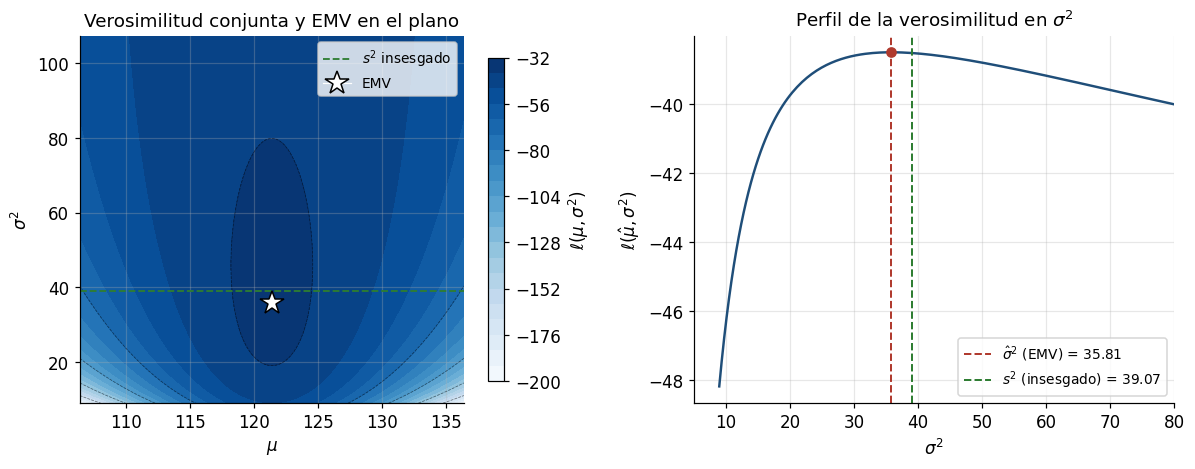

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))

# izquierda: log-verosimilitud conjunta en el plano (mu, sigma^2)
malla_mu = np.linspace(mu_mle - 15, mu_mle + 15, 260)
malla_s2 = np.linspace(0.25 * sigma2_mle, 3.0 * sigma2_mle, 260)
MU, S2 = np.meshgrid(malla_mu, malla_s2)

suma_cuadrados = ((obs[None, None, :] - MU[:, :, None]) ** 2).sum(axis=2)
ELL = -n_obs / 2 * np.log(2 * np.pi) - n_obs / 2 * np.log(S2) - suma_cuadrados / (2 * S2)

niveles = axs[0].contourf(MU, S2, ELL, levels=22, cmap="Blues")
axs[0].contour(MU, S2, ELL, levels=niveles.levels[::4], colors="black", linewidths=0.5, alpha=0.5)
axs[0].axhline(s2_insesg, color=VERDE, linestyle="--", linewidth=1.2,
               label=r"$s^2$ insesgado")
axs[0].plot(mu_mle, sigma2_mle, marker="*", markersize=16, color="white",
            markeredgecolor="black", linewidth=0.8, label="EMV")
fig.colorbar(niveles, ax=axs[0], shrink=0.88, label=r"$\ell(\mu, \sigma^2)$")
axs[0].set_xlabel(r"$\mu$")
axs[0].set_ylabel(r"$\sigma^2$")
axs[0].set_title("Verosimilitud conjunta y EMV en el plano")
axs[0].legend(fontsize=9, loc="upper right")

# derecha: perfil de la verosimilitud con mu fijo en el EMV
perfil = (-n_obs / 2 * np.log(2 * np.pi) - n_obs / 2 * np.log(malla_s2)
          - ((obs - mu_mle) ** 2).sum() / (2 * malla_s2))

axs[1].plot(malla_s2, perfil, color=AZUL, linewidth=1.6)
axs[1].axvline(sigma2_mle, color=ROJO, linestyle="--", linewidth=1.3,
               label=rf"$\hat\sigma^2$ (EMV) = {sigma2_mle:.2f}")
axs[1].axvline(s2_insesg, color=VERDE, linestyle="--", linewidth=1.3,
               label=rf"$s^2$ (insesgado) = {s2_insesg:.2f}")
axs[1].plot(sigma2_mle, perfil.max(), "o", color=ROJO)
axs[1].set_xlabel(r"$\sigma^2$")
axs[1].set_xlim(5, 80)
axs[1].set_ylabel(r"$\ell(\hat\mu, \sigma^2)$")
axs[1].set_title(r"Perfil de la verosimilitud en $\sigma^2$")
axs[1].legend(fontsize=9)

plt.tight_layout()
plt.show()


## Notas de validación

- Las cuatro estimaciones de la sección 1 se calculan sobre los 10 pesos observados:
  $\bar x = 798.9$ g, $s^2 = 166.9/9 = 18.5444$ g$^2$, $s = 4.3063$ g y $\hat p = 5/10 = 0.5$. La
  suma de cuadrados se evalúa en la forma $\sum x_i^2 - (\sum x_i)^2/n$, que evita la cancelación de
  cifras significativas que produce restar dos sumatorias grandes.
- El insesgamiento es una propiedad de la fórmula del estimador y no del número puntual que arroja una
  muestra concreta: $\bar x = 798.9$ no es "insesgado", lo es el estimador $\bar X$ para cualquier
  muestra. El sesgo se decide sobre $E[T]$, no sobre $t$.
- Las simulaciones Monte Carlo usan semilla fija y entre $10^5$ y $2 \times 10^5$ ensayos. Los sesgos
  residuales de las tablas son del orden del error estándar de la media simulada,
  $\operatorname{sd}(T)/\sqrt{M}$, y se imprimen junto al valor para poder distinguirlos de un sesgo
  real del estimador. Para el sesgo de $\bar X^2$ (sección 2.c) se usa la identidad
  $\bar X^2 - \mu^2 = (\bar X - \mu)^2 + 2\mu(\bar X - \mu)$: como $E[\bar X - \mu] = 0$, el sesgo se
  estima como la media muestral de $(\bar X - \mu)^2$, de varianza $2(\sigma^2/n)^2/M$, mientras que
  restar $\mu^2$ a la media simulada de $\bar X^2$ arrastra además un término $4\mu^2\sigma^2/(nM)$
  que ensombrece el resultado cuando $\mu$ es grande respecto de $\sigma/\sqrt{n}$.
- Comprobaciones numéricas realizadas: ecuación de verosimilitud contrastada con una búsqueda directa
  sobre grilla fina (secciones 4 y 5), anulación de ambas derivadas parciales en el EMV de la sección
  6, razón exacta $\hat\sigma^2/s^2 = (n-1)/n$, y eficiencia relativa $\operatorname{EFF} = 9/8$
  contrastada con la varianza simulada de los dos estimadores de la sección 3.
- En la sección 3 los dos estimadores son insesgados, de modo que la comparación de varianzas
  equivale a la de errores cuadráticos medios; la eficiencia relativa solo se define entre estimadores
  del mismo parámetro y con el mismo tamaño de muestra.
- Los EMV no garantizan insesgamiento: en la sección 5 el de $p$ resulta insesgado y en la 6 el de
  $\sigma^2$ no lo es, con un sesgo que se anula como $1/n$. En ambos casos la varianza del estimador
  también decrece con $n$, de modo que los EMV son consistentes.

Referencias: Walpole, R. - Probabilidad y estadística para ingeniería y ciencias. Casella, G. y
Berger, R. - Statistical Inference. Mood, A., Graybill, F. y Boes, D. - Introducción a la teoría de
la estadística.